# Segmentación de canciones: Evaluación

Explorar grupos musicales por características de canciones.

Silhouette y estabilidad entre dos semillas; el género no se usa para ajustar los clusters. Los grupos no equivalen necesariamente a géneros musicales.

Consulta la [metodología](../docs/metodologia.md). Los reportes corresponden a la última ejecución de cada etapa.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("spotify_segmentation")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from spotify_segmentation.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Segmentación de canciones: evaluacion

La segmentación es **similar** entre las dos semillas revisadas (ARI **1.0000**; corte descriptivo 0,8). La proyección de dos componentes conserva **43.88%** de la varianza. Los perfiles están expresados en las unidades originales. Los números de cluster no tienen significado ordinal ni equivalen a segmentos de negocio validados.


,cluster,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,registros
0,0,0.5397,0.3945,-10.3550,0.0543,0.6662,0.0701,0.1810,0.4042,114.3272,213467.6830,4637
1,1,0.6872,0.7348,-6.4764,0.0949,0.2064,0.0539,0.2020,0.6964,121.6512,212869.2565,7676
2,2,0.5711,0.6768,-11.1877,0.8249,0.7338,0.0112,0.6723,0.4575,103.0946,212840.4221,244
3,3,0.4788,0.8143,-6.1146,0.0822,0.0669,0.2535,0.2504,0.3081,135.2028,262526.6903,5841
4,4,0.3445,0.1984,-20.6047,0.0525,0.8284,0.7717,0.1772,0.1748,103.3760,235279.1573,1602


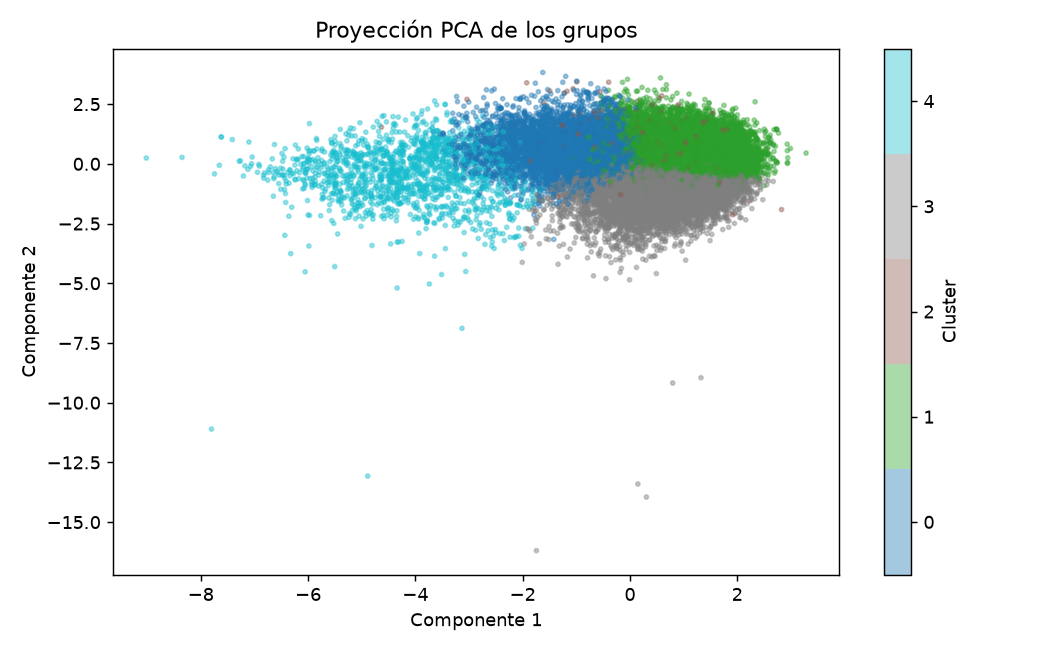

In [2]:
from spotify_segmentation.flow import run_stage
metricas, comentario = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comentario))
from spotify_segmentation.presentation import display_evaluation
display_evaluation(PROJECT_ROOT, metricas)


## Alertas

Avisos agrupados con descripción y acción sugerida. Los errores no se ocultan; no registrar warnings no garantiza que el análisis sea válido.

In [ ]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from spotify_segmentation.informe import generar_informe
generar_informe(PROJECT_ROOT)
